# Step 1: Multi-Cloud Dataset Ingestion & FOCUS 1.0 Data Warehouse
**Abhi Cloud Tech — Enterprise FinOps & Multi-Cloud Optimization Platform**  
*Lead Architect: Abhishek*

---

### Executive Overview & Industry Context
In modern multi-cloud enterprises (AWS, Azure, Google Cloud Platform), cloud billing data is fragmented across proprietary billing exports (AWS Cost and Usage Reports (CUR), Azure Cost Management exports, and GCP Cloud Billing BigQuery exports). 

The **FinOps Open Cost and Usage Specification (FOCUS 1.0)** normalizes heterogeneous billing columns into standard dimensions:
- `ChargePeriodStart` & `ChargePeriodEnd` (UTC Timestamp)
- `ProviderName` (`AWS`, `Azure`, `Google Cloud`)
- `ServiceName` (Standardized Cloud Service)
- `ResourceName` / `ResourceId` (Unique Cloud URN)
- `BilledCost` (Invoice Charge) & `EffectiveCost` (Amortized / Net Charge)
- `PricingQuantity` & `PricingUnit`

### Multi-Cloud Machine Image & Snapshot Waste
A major source of real-world enterprise waste is **unattached disk snapshots and stale machine images**:
1. **AWS EBS Snapshots & AMIs (`AmazonEC2-Snapshots`)**: Standard rate $0.05/GB-month. When EC2 instances are terminated, EBS volume snapshots and AMIs remain indefinitely without automated retention lifecycles.
2. **Azure Managed Disk Snapshots (`Microsoft.Compute/snapshots`)**: Differential/full disk snapshots and Compute Gallery Images billed continuously at ~$0.05/GB-month.
3. **GCP Machine Images & PD Snapshots (`Compute Engine - Snapshots & Images`)**: Persistent disk snapshots and custom boot machine images billed at $0.026 - $0.05/GB-month.

This notebook loads the FOCUS 1.0 dataset, audits telemetry, and inspects the enterprise SQLite warehouse.


### Block 1: Imports and Directory Configuration


In [1]:
import os
import sys
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.database import FinOpsDatabase, load_focus_dataframe
db = FinOpsDatabase()
print(f"Data Warehouse Path: {db.db_path}")
sns.set_theme(style="whitegrid")
%matplotlib inline


FinOps Data Warehouse initialized at: C:\Users\M Abhishek Reddy\.gemini\antigravity\scratch\cloud-finops-intelligence\data\finops_warehouse.db
Data Warehouse Path: C:\Users\M Abhishek Reddy\.gemini\antigravity\scratch\cloud-finops-intelligence\data\finops_warehouse.db


### Block 2: Load FOCUS 1.0 Warehouse Telemetry


In [2]:
df = load_focus_dataframe()
print(f"Loaded {len(df):,} normalized FOCUS 1.0 records.")
print(f"Date Range: {df['Date'].min()} to {df['Date'].max()} ({df['Date'].nunique()} unique days)")
print(f"Cloud Providers: {df['CloudProvider'].unique().tolist()}")
print(f"Departments: {df['Department'].unique().tolist()}")
df.head(5)


Loaded 32,850 normalized FOCUS 1.0 records.
Date Range: 2025-01-01 to 2025-12-31 (365 unique days)
Cloud Providers: ['AWS', 'Azure', 'GCP']
Departments: ['AI/ML Research', 'Core Engineering', 'Customer Portal', 'Data Platform', 'Finance & Analytics']


,RecordId,Date,CloudProvider,Department,ServiceName,ServiceCategory,Service,RegionId,RegionName,ResourceId,...,TagEnvironment,Avg_CPU_Utilization_Pct,MaxCpuUtilizationPct,vCPU_Hours,Memory_GB_Hours,Storage_TB,Data_Egress_GB,Is_Anomaly,Anomaly_Type,Est_Waste_Cost_USD
0,REC-000-AWS-5aee165f,2025-01-01,AWS,AI/ML Research,AmazonEC2,Compute,AmazonEC2 (Compute),us-east-1,US East (N. Virginia),arn:aws:ec2:us-east-1:942182019482:instance/i-...,...,Research-Lab,34.7,49.2,6598.6,17071.4,47.97,526.9,0,None,0.00
1,REC-000-AWS-326e6da8,2025-01-01,AWS,AI/ML Research,AmazonS3,Storage,AmazonS3 (Storage),eu-central-1,Europe (Frankfurt),arn:aws:s3:::abhi-data-lake-ai-ml-research-326...,...,Research-Lab,51.8,77.1,2829.0,7973.6,12.05,188.6,1,Unattached Volumes & Orphan Snapshots,165.22
2,REC-000-AWS-84d55a4a,2025-01-01,AWS,AI/ML Research,AmazonRDS,Database,AmazonRDS (Database),us-east-1,US East (N. Virginia),arn:aws:rds:us-east-1:942182019482:db:abhi-db-...,...,Research-Lab,57.8,72.0,4240.0,12458.0,21.73,409.4,0,None,0.00
3,REC-000-AWS-0d2fe0ce,2025-01-01,AWS,AI/ML Research,AmazonEKS,Containers,AmazonEKS (Containers),eu-central-1,Europe (Frankfurt),arn:aws:eks:us-east-1:942182019482:cluster/abh...,...,Research-Lab,29.7,51.2,3293.5,8463.2,34.40,178.1,0,None,0.00
4,REC-000-AWS-8e92f0c4,2025-01-01,AWS,AI/ML Research,AmazonCloudFront,Network,AmazonCloudFront (Network),us-east-1,US East (N. Virginia),arn:aws:cloudfront::942182019482:distribution/...,...,Research-Lab,40.8,54.4,3968.9,13995.7,25.61,138.9,0,None,0.00


### Block 3: Provider Cost Share & Resource Type Breakdown


C:\Users\M Abhishek Reddy\AppData\Local\Temp\ipykernel_9504\2560669130.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_spend.values, y=cat_spend.index, palette='Blues_r')


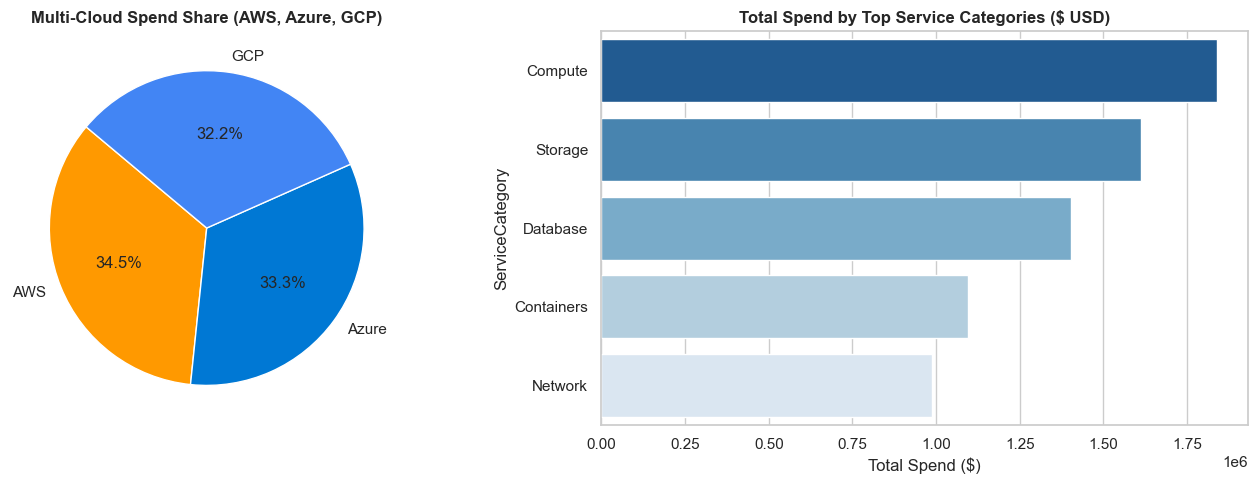

In [3]:
plt.figure(figsize=(14, 5))

# 1. Total Spend by Provider
plt.subplot(1, 2, 1)
provider_spend = df.groupby('CloudProvider')['DailyCost_USD'].sum()
colors = ['#ff9900', '#0078d4', '#4285f4']
plt.pie(provider_spend, labels=provider_spend.index, autopct='%1.1f%%', colors=colors, startangle=140)
plt.title("Multi-Cloud Spend Share (AWS, Azure, GCP)", fontsize=12, fontweight='bold')

# 2. Spend by Top Service Categories
plt.subplot(1, 2, 2)
cat_spend = df.groupby('ServiceCategory')['DailyCost_USD'].sum().sort_values(ascending=False).head(5)
sns.barplot(x=cat_spend.values, y=cat_spend.index, palette='Blues_r')
plt.title("Total Spend by Top Service Categories ($ USD)", fontsize=12, fontweight='bold')
plt.xlabel("Total Spend ($)")

plt.tight_layout()
plt.show()
